# Proyecto final - Código de solución

In [1]:
# Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils import shuffle
from lightgbm import LGBMClassifier

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from imblearn.over_sampling import SMOTE

# 1. Comprensión del trabajo

La empresa Interconnect desea pronosticar la tasa de cancelación de clientes para poder tomar medidas al detecar si un cliente va a cancelar su suscripción, se le ofreceran códigos promocionales o planes especiales. 

El problema será abordado como un tarea de clasificación binaria, donde la variable objetivo indicará si un cliente canceló o no su sucripción.

# 2. Lectura de los datos

In [2]:
contract_df = pd.read_csv('../datasets/final_provider/contract.csv')
internet_df = pd.read_csv('../datasets/final_provider/internet.csv')
personal_df = pd.read_csv('../datasets/final_provider/personal.csv')
phone_df = pd.read_csv('../datasets/final_provider/phone.csv')

In [3]:
contract_df.sample(5)

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
3318,5016-ETTFF,2019-01-01,2019-11-01 00:00:00,Month-to-month,No,Mailed check,29.50,255.25
6438,3551-HUAZH,2019-09-01,2019-10-01 00:00:00,Month-to-month,Yes,Electronic check,74.40,74.4
6802,5626-MGTUK,2018-06-01,No,Month-to-month,Yes,Bank transfer (automatic),89.10,1879.25
1978,0602-DDUML,2015-05-01,No,Two year,No,Mailed check,69.75,3894.4
1039,9948-YPTDG,2016-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Electronic check,79.45,3013.05


In [4]:
internet_df.sample(5)

,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
4384,9152-AMKAK,DSL,Yes,No,Yes,Yes,Yes,Yes
4993,7994-XIRTR,DSL,No,No,Yes,Yes,No,Yes
3443,5227-JSCFE,DSL,Yes,Yes,Yes,Yes,No,No
3349,6425-YQLLO,Fiber optic,No,No,Yes,Yes,Yes,Yes
119,6440-DKQGE,DSL,No,Yes,Yes,No,Yes,No


In [5]:
personal_df.sample(5)

,customerID,gender,SeniorCitizen,Partner,Dependents
1037,4581-LNWUM,Female,0,No,No
6616,9600-NAXZN,Male,0,No,No
1902,1951-IEYXM,Male,0,Yes,Yes
6171,1658-XUHBX,Female,1,Yes,Yes
5673,6260-XLACS,Male,0,No,No


In [6]:
phone_df.sample(5)

,customerID,MultipleLines
5431,1099-GODLO,No
6181,2025-JKFWI,Yes
258,2294-SALNE,No
769,7408-OFWXJ,Yes
3551,9278-VZKCD,Yes


Los datos fueron cargados correctamente.

# 3. Comprensión de los datos

In [7]:
print('Número de registros')
print('==='*10)
print('Contract:', contract_df.shape)
print('internet:', internet_df.shape)
print('Contract:', personal_df.shape)
print('Contract:', phone_df.shape)

Número de registros
Contract: (7043, 8)
internet: (5517, 8)
Contract: (7043, 5)
Contract: (6361, 2)


Tipos de de datos

In [8]:
contract_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   BeginDate         7043 non-null   str    
 2   EndDate           7043 non-null   str    
 3   Type              7043 non-null   str    
 4   PaperlessBilling  7043 non-null   str    
 5   PaymentMethod     7043 non-null   str    
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   str    
dtypes: float64(1), str(7)
memory usage: 440.3 KB


In [9]:
internet_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5517 entries, 0 to 5516
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   customerID        5517 non-null   str  
 1   InternetService   5517 non-null   str  
 2   OnlineSecurity    5517 non-null   str  
 3   OnlineBackup      5517 non-null   str  
 4   DeviceProtection  5517 non-null   str  
 5   TechSupport       5517 non-null   str  
 6   StreamingTV       5517 non-null   str  
 7   StreamingMovies   5517 non-null   str  
dtypes: str(8)
memory usage: 344.9 KB


In [10]:
personal_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerID     7043 non-null   str  
 1   gender         7043 non-null   str  
 2   SeniorCitizen  7043 non-null   int64
 3   Partner        7043 non-null   str  
 4   Dependents     7043 non-null   str  
dtypes: int64(1), str(4)
memory usage: 275.2 KB


In [11]:
phone_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6361 entries, 0 to 6360
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerID     6361 non-null   str  
 1   MultipleLines  6361 non-null   str  
dtypes: str(2)
memory usage: 99.5 KB


Dentro de los datasets detecte tipos de datos incorrectos:
- Columnas tabla contract
    - BeginDate devería ser de tipo fecha
    - EndDate devería ser de tipo fecha
    - PaperlessBilling devería de ser de tipo booleano
    - TotalCharges devería ser de tipo flaot

- columnas de la tabla internet:
    - OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, sería conveniente que fueran de tipo booleano.

- Columnas dentro de la tabla personal:
    - Partner, Dependents, sería conveniente que estuvieran en booleano.

- Columnas dentro de la tabla phone:
    - MultipleLines, devería ser booleano.

**Valores ausentes**

In [12]:
print('Contract')
print('==='*10)
print(contract_df.isna().sum())
print()

Contract
customerID          0
BeginDate           0
EndDate             0
Type                0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
dtype: int64



In [13]:
print('Internet')
print('==='*10)
print(internet_df.isna().sum())
print()

Internet
customerID          0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
dtype: int64



In [14]:
print('Personal')
print('==='*10)
print(personal_df.isna().sum())
print()

Personal
customerID       0
gender           0
SeniorCitizen    0
Partner          0
Dependents       0
dtype: int64



In [15]:
print('Phone')
print('==='*10)
print(phone_df.isna().sum())

Phone
customerID       0
MultipleLines    0
dtype: int64


No se detectaron valores ausentes, los datos esta correcto en esta cuestión.

**Registros duplicados**

In [16]:
print('Registros duplicados')
print('Tabla contract', contract_df.duplicated().sum())
print('Tabla internet', internet_df.duplicated().sum())
print('Tabla personal', personal_df.duplicated().sum())
print('Tabla phone', phone_df.duplicated().sum())

Registros duplicados
Tabla contract 0
Tabla internet 0
Tabla personal 0
Tabla phone 0


Tampoco se encontraron registros duplicados, los registros estan adecuados en esta cuestión.

# 4. Análisis Exploratorio

In [17]:
contract_copy = contract_df.copy()
internet_copy = internet_df.copy()

#### ¿Qué proporción de clientes cancela su suscripción?

In [18]:
contract_copy['EndDate'].unique()

<StringArray>
[                 'No', '2019-12-01 00:00:00', '2019-11-01 00:00:00',
 '2019-10-01 00:00:00', '2020-01-01 00:00:00']
Length: 5, dtype: str

In [19]:
# Crear una nueva columna
contract_copy['canceled'] = np.where(contract_copy['EndDate'] == 'No', 0, 1)

contract_copy.head()

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,canceled
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5,0
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65,1


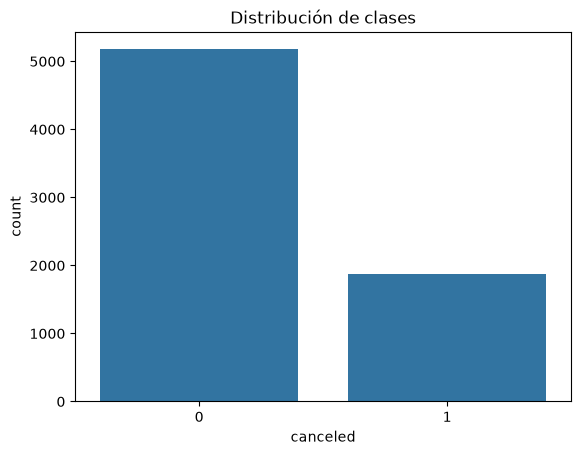

In [20]:
# Balanceo de clases
sns.countplot(contract_copy, x='canceled')
plt.title('Distribución de clases')

plt.show()

In [21]:
print(contract_copy['canceled'].value_counts(normalize=True))

canceled
0    0.73463
1    0.26537
Name: proportion, dtype: float64


El dataframe no contenia la columna objetivo, se puede observar que hay una columna que indica la fecha final (fecha cuando el cliente dejo los servicios) pero en la misma columna se indica que no se ha dejado el servicio con "No" por lo que no esta en un formato adecuado, es por eso que se necesito crear una nueva columna adecuada con 0 para indicar si que el cliente no ha dejado los servicios y 1 para aquellos clientes que si lo ha hecho.

El desbalance en las clases es evidente, como se esperaba hay menos clientes que han dejado los servicios, 73% no han cancelado y 26 si lo han hecho.

#### ¿Existe relación entre la antigüedad del cliente y la cancelación?

In [22]:
# Fecha
reference_date = '2020-02-01 00:00:00'

In [23]:
contract_copy.head()

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,canceled
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5,0
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [24]:
contract_copy['BeginDate'].unique()

<StringArray>
['2020-01-01', '2017-04-01', '2019-10-01', '2016-05-01', '2019-09-01',
 '2019-03-01', '2018-04-01', '2019-04-01', '2017-07-01', '2014-12-01',
 '2019-01-01', '2018-10-01', '2015-04-01', '2015-09-01', '2018-01-01',
 '2014-05-01', '2015-10-01', '2014-03-01', '2018-05-01', '2019-11-01',
 '2019-02-01', '2016-01-01', '2017-08-01', '2015-12-01', '2014-02-01',
 '2018-06-01', '2019-12-01', '2017-11-01', '2019-06-01', '2016-04-01',
 '2017-02-01', '2018-12-01', '2014-04-01', '2018-09-01', '2014-11-01',
 '2016-07-01', '2015-02-01', '2018-07-01', '2014-08-01', '2016-03-01',
 '2018-08-01', '2014-10-01', '2015-06-01', '2016-08-01', '2019-05-01',
 '2017-03-01', '2016-02-01', '2017-09-01', '2014-09-01', '2017-12-01',
 '2016-12-01', '2017-06-01', '2015-05-01', '2016-10-01', '2016-09-01',
 '2019-08-01', '2019-07-01', '2017-05-01', '2017-10-01', '2014-07-01',
 '2018-03-01', '2015-01-01', '2018-11-01', '2015-03-01', '2018-02-01',
 '2016-06-01', '2015-08-01', '2015-11-01', '2014-06-01', '2017-

In [25]:
# Convertir las columna a datetime
contract_copy['BeginDate'] = pd.to_datetime(contract_copy['BeginDate'], errors='coerce')

# le agregamos la fecha de contrado valido
contract_copy['EndDateReal'] = contract_copy['EndDate'].replace("No", reference_date)
contract_copy['EndDateReal'] = pd.to_datetime(contract_copy['EndDateReal'], errors='coerce')


# Columna antiguedad
antique_days = (contract_copy['EndDateReal'] - contract_copy['BeginDate']).dt.days
contract_copy['antique'] = antique_days.fillna(0).astype(int)

display(contract_copy.head())

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,canceled,EndDateReal,antique
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,2020-02-01,31
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5,0,2020-02-01,1036
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15,1,2019-12-01,61
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,2020-02-01,1371
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65,1,2019-11-01,61


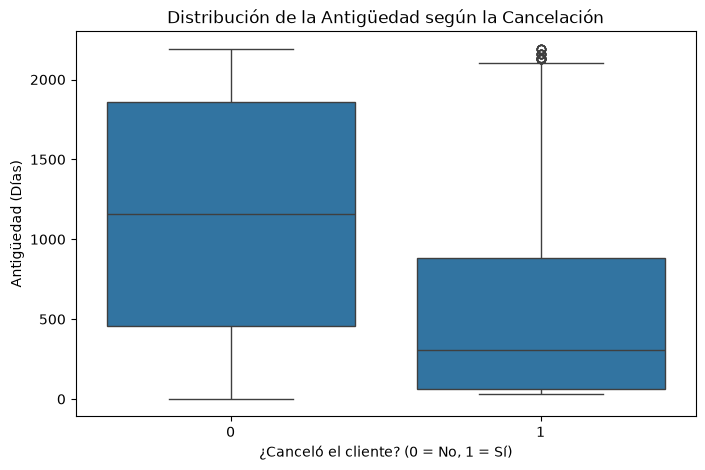

In [26]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=contract_copy, x="canceled", y="antique")

plt.title("Distribución de la Antigüedad según la Cancelación")
plt.xlabel("¿Canceló el cliente? (0 = No, 1 = Sí)")
plt.ylabel("Antigüedad (Días)")
plt.show()

Como la columna antiguedad no se encuentra se tuvo que crear, por lo que antes se comprobo el formato de fecha al igual que con el comando unique revisamos si no existe un valor que puedo generar error como en el caso de la columna EndDate y "No", luego de las comprobaciones convertimos las columnas a tipo de dato datime y finalmente calculamos la antiguedad del cliente tomando en cuenta la hasta la fecha valida que indica la tarea (fecha hasta la cual se tiene que tomar en cuenta).

En cuanto a la distribución de la antiguedad según las clases objetivo: rápidamente se puede interpretar que para los usuarios que no cancelaron es diferente a los que si cancelaron, los clientes que si canceron normalmente lo hicieron con poco tiempo en comparación con los que se mantienen. Otro punto importante que se puede observar es que algunos clientes que cancelaron lo hicieron incluso en los primeros días de unirse.

#### ¿La cantidad de servicios contratados está relacionado con la cancelación?

In [27]:
print('DataFrame contract')
display(contract_copy.sample(3))
print('DataFrame internet')
display(internet_copy.sample(3))

DataFrame contract


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,canceled,EndDateReal,antique
5973,2324-EFHVG,2014-10-01,No,Two year,Yes,Bank transfer (automatic),104.4,6692.65,0,2020-02-01,1949
6892,1545-ACTAS,2016-02-01,No,One year,Yes,Bank transfer (automatic),99.7,4977.2,0,2020-02-01,1461
3981,1200-TUZHR,2019-06-01,No,Month-to-month,No,Electronic check,85.2,695.75,0,2020-02-01,245


DataFrame internet


,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
4401,4391-RESHN,Fiber optic,No,No,Yes,Yes,Yes,Yes
4853,1496-GGSUK,DSL,No,No,No,No,No,No
3130,6752-APNJL,DSL,Yes,Yes,No,No,No,No


In [28]:
# verificar los valores de la columna IntenetService
internet_copy['InternetService'].unique()

<StringArray>
['DSL', 'Fiber optic']
Length: 2, dtype: str

In [29]:
# ajustar las columnas de servicio
internet_copy['InternetServiceActive'] = internet_copy['InternetService'].replace(['DSL', 'Fiber optic'], 1).fillna(0).astype(int)

internet_copy.sample(5)

internet_columns_transform = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

for col in internet_columns_transform:
    internet_copy[col] = np.where(internet_copy[col] == 'Yes', 1, 0)

internet_copy.sample(5)

,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,InternetServiceActive
1989,4277-PVRAN,Fiber optic,0,0,0,0,1,0,1
1502,6637-KYRCV,DSL,0,1,0,0,0,0,1
5193,0898-XCGTF,Fiber optic,0,0,0,0,1,1,1
25,8773-HHUOZ,DSL,0,0,0,0,1,1,1
3743,9972-NKTFD,DSL,0,1,0,1,0,0,1


In [30]:
# Contar los servicios por cliente
internet_copy['services'] = internet_copy[['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'InternetServiceActive']].sum(axis=1)

internet_copy.sample(5)

,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,InternetServiceActive,services
514,9411-TPQQV,DSL,1,0,0,1,1,1,1,5
5515,8361-LTMKD,Fiber optic,0,0,0,0,0,0,1,1
4143,5569-OUICF,Fiber optic,0,0,0,1,1,1,1,4
1703,5453-YBTWV,Fiber optic,1,1,1,1,1,0,1,6
4120,8780-IXSTS,Fiber optic,0,1,0,0,1,0,1,3


In [31]:
# Convinar las tablas
contract_internet = pd.merge(contract_copy, internet_copy, how='inner', on='customerID')

contract_internet.sample(5)

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,canceled,EndDateReal,antique,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,InternetServiceActive,services
3812,2359-KLTEK,2016-09-01,No,Month-to-month,Yes,Bank transfer (automatic),94.90,3848,0,2020-02-01,1248,Fiber optic,0,0,1,0,1,1,1,4
3274,4902-OHLSK,2017-08-01,2020-01-01 00:00:00,Month-to-month,No,Electronic check,98.65,2862.75,1,2020-01-01,883,Fiber optic,0,0,0,1,1,1,1,4
364,8847-GEOOQ,2015-02-01,No,Month-to-month,Yes,Bank transfer (automatic),60.20,3582.4,0,2020-02-01,1826,DSL,0,1,1,1,1,1,1,6
1373,8887-IPQNC,2019-07-01,No,Month-to-month,Yes,Mailed check,44.25,313.45,0,2020-02-01,215,DSL,0,0,0,0,0,0,1,1
5403,0530-IJVDB,2014-04-01,No,Two year,Yes,Electronic check,114.60,7882.5,0,2020-02-01,2132,Fiber optic,1,1,1,1,1,1,1,7


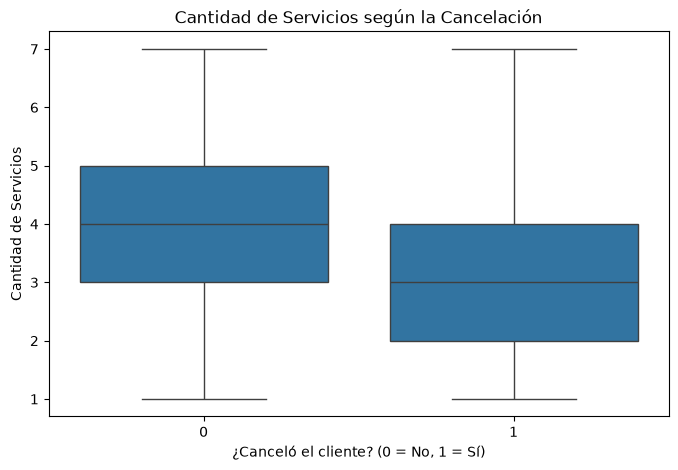

In [32]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=contract_internet,
    x="canceled",
    y="services"
)

plt.title("Cantidad de Servicios según la Cancelación")
plt.xlabel("¿Canceló el cliente? (0 = No, 1 = Sí)")
plt.ylabel("Cantidad de Servicios")
plt.show()

Para completar esta tarea se corrijio los tipos de datos de las columnas que indican con que serivcio cuenta el cliente, se realizo la suma de los servicios y finalmente se unio la tabla contract e internet.

En la gráfica se puede observar que los usuarios que no hicieron churn tienen mayor cantidad de servicios que los clientes que si hicieron churn. Esto nos revela que posiblemente los clientes que tienen más servicios disfrutan ser clientes de interconnect.

#### ¿Existen diferencias en la cancelación según el tipo de plan?

In [33]:
# Verificación de los tipos de contrato
contract_copy['Type'].unique()

<StringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str

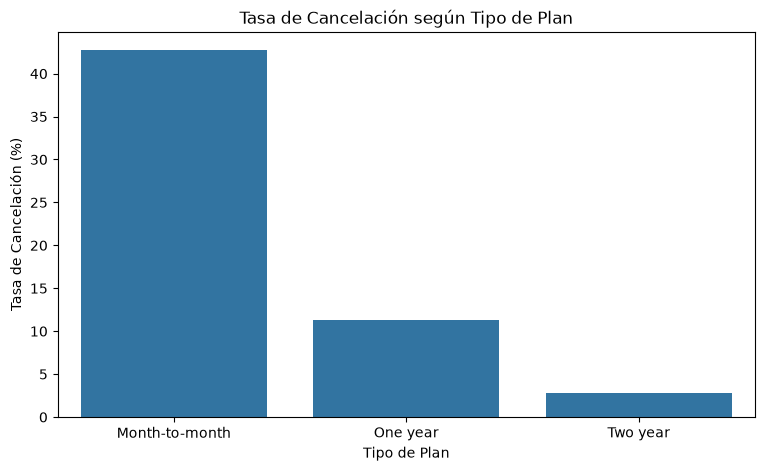

In [34]:
cancel_rate = (
    contract_copy
    .groupby("Type")["canceled"]
    .mean()
    .reset_index()
)

cancel_rate["canceled"] *= 100

plt.figure(figsize=(9, 5))

sns.barplot(
    data=cancel_rate,
    x="Type",
    y="canceled"
)

plt.title("Tasa de Cancelación según Tipo de Plan")
plt.xlabel("Tipo de Plan")
plt.ylabel("Tasa de Cancelación (%)")

plt.show()

Se verifico los tipos de contratos únicos, para luego obtener el proporción por tipo.

Se observa diferencia en la tasa de cancelación entre los tipos de plan o contratos. El plan mensual presenta la mayor proporción de cancelación, mientras que el contrato por 2 años presenta la menor. Esto sugiere que el tipo de plan podría estar relacionado con la cancelación y, por lo tanto, la variable podría ser relevante para el modelo de clasificación.

# 5. Preparación de los datos

## Unir DataFrames

In [35]:
# Ver si se repite customerID en alguna tabla
# Si lo hubieras sería por que se tiene un realación de uno a muchos
print(f'contract: {contract_df['customerID'].duplicated().sum()}')
print(f'internet: {internet_df['customerID'].duplicated().sum()}')
print(f'personal: {personal_df['customerID'].duplicated().sum()}')
print(f'phone: {phone_df['customerID'].duplicated().sum()}')

contract: 0
internet: 0
personal: 0
phone: 0


In [36]:
contract_internet_phone = pd.merge(contract_internet, phone_df, how='inner', on='customerID')

all_df = pd.merge(contract_internet_phone, personal_df, how='inner', on='customerID')

all_df.sample(10)

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,canceled,EndDateReal,...,TechSupport,StreamingTV,StreamingMovies,InternetServiceActive,services,MultipleLines,gender,SeniorCitizen,Partner,Dependents
3299,9102-OXKFY,2015-03-01,No,Two year,No,Credit card (automatic),54.15,3116.15,0,2020-02-01,...,0,0,0,1,2,Yes,Male,0,No,No
3175,8065-BVEPF,2014-09-01,No,Month-to-month,Yes,Bank transfer (automatic),99.10,6496.15,0,2020-02-01,...,0,1,1,1,5,No,Male,1,No,No
1688,6486-LHTMA,2017-07-01,No,One year,Yes,Electronic check,90.70,2835.5,0,2020-02-01,...,0,1,0,1,3,Yes,Female,1,Yes,No
2294,7593-XFKDI,2019-11-01,2019-12-01 00:00:00,Month-to-month,No,Mailed check,46.30,46.3,1,2019-12-01,...,0,0,0,1,1,No,Male,0,No,No
3371,3162-ZJZFU,2015-09-01,No,Month-to-month,Yes,Electronic check,92.55,4779.45,0,2020-02-01,...,1,1,0,1,4,No,Male,0,Yes,Yes
4,1452-KIOVK,2018-04-01,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,0,2020-02-01,...,0,1,0,1,3,Yes,Male,0,No,Yes
1762,8245-UMPYT,2018-06-01,2019-10-01 00:00:00,Month-to-month,Yes,Electronic check,96.40,1581.2,1,2019-10-01,...,0,1,1,1,3,Yes,Female,1,No,No
1092,7776-QGYJC,2016-11-01,No,Month-to-month,Yes,Bank transfer (automatic),81.50,3107.3,0,2020-02-01,...,1,0,0,1,3,No,Female,0,Yes,Yes
4553,1465-VINDH,2019-02-01,2019-12-01 00:00:00,Month-to-month,Yes,Credit card (automatic),102.10,1068.85,1,2019-12-01,...,0,1,1,1,5,Yes,Female,0,Yes,Yes
4758,6257-DTAYD,2014-03-01,No,Two year,Yes,Credit card (automatic),104.15,7365.3,0,2020-02-01,...,1,1,1,1,5,Yes,Male,0,Yes,No


Se comprobo el tiepo de relación entre cada tabla, como la relación es de uno a uno por eso simplemente hacemos merge.

## Corrección de tipos de datos

Columna TotalCharges de string a numerico

In [37]:
# correción de tipo de datos
all_df['TotalCharges'] = pd.to_numeric(all_df['TotalCharges'], errors='coerce')

print(f'Valores nullos: {all_df['TotalCharges'].isna().sum()}')
all_df['TotalCharges'] = all_df['TotalCharges'].fillna(0)
print(f'Valores nullos: {all_df['TotalCharges'].isna().sum()}')

Valores nullos: 3
Valores nullos: 0


Se utilizo error coerce por que hay un valor '  ' dentro de la columna. 

In [38]:
# Valores booleanos
all_df['PaperlessBilling'] = np.where(all_df['PaperlessBilling'] == 'Yes', 1, 0)
all_df['Partner'] = np.where(all_df['PaperlessBilling'] == 'Yes', 1, 0)
all_df['MultipleLines'] = np.where(all_df['MultipleLines'] == 'Yes', 1, 0)
all_df['Dependents'] = np.where(all_df['PaperlessBilling'] == 'Yes', 1, 0)

all_df.head()

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,canceled,EndDateReal,...,TechSupport,StreamingTV,StreamingMovies,InternetServiceActive,services,MultipleLines,gender,SeniorCitizen,Partner,Dependents
0,5575-GNVDE,2017-04-01,No,One year,0,Mailed check,56.95,1889.50,0,2020-02-01,...,0,0,0,1,3,0,Male,0,0,0
1,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,1,Mailed check,53.85,108.15,1,2019-12-01,...,0,0,0,1,3,0,Male,0,0,0
2,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,1,Electronic check,70.70,151.65,1,2019-11-01,...,0,0,0,1,1,0,Female,0,0,0
3,9305-CDSKC,2019-03-01,2019-11-01 00:00:00,Month-to-month,1,Electronic check,99.65,820.50,1,2019-11-01,...,0,1,1,1,4,1,Female,0,0,0
4,1452-KIOVK,2018-04-01,No,Month-to-month,1,Credit card (automatic),89.10,1949.40,0,2020-02-01,...,0,1,0,1,3,1,Male,0,0,0


Se corrigieron algunos tipos de datos booleanos que se encontraban como strings.

## Separación de variables predictoras y objetivo

In [39]:
# Variable objetivo
y = all_df['canceled']

features = [
    'Type',
    'PaperlessBilling',
    'PaymentMethod',
    'MonthlyCharges',
    'TotalCharges',
    'antique',
    'InternetService',
    'services',
    'MultipleLines'
]

X = all_df[features]

print(f'Tamaño target: {y.shape}')
print(f'Tamaño features: {X.shape}')

display(X.sample(5))

Tamaño target: (4835,)
Tamaño features: (4835, 9)


,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,antique,InternetService,services,MultipleLines
503,Month-to-month,1,Mailed check,81.00,1683.70,610,Fiber optic,3,0
2553,Month-to-month,1,Bank transfer (automatic),69.15,235.00,92,DSL,4,1
3693,Month-to-month,1,Electronic check,84.50,453.75,153,Fiber optic,3,1
1118,Month-to-month,1,Electronic check,64.95,493.65,215,DSL,4,0
3531,One year,1,Electronic check,66.20,4692.55,2163,DSL,3,1


Se seleccionaron únicamente las características que podrían aportar valor a la predicción.

In [40]:
numerical_columns = [
    'MonthlyCharges',
    'TotalCharges',
    'antique',
    'services'
]

categorical_columns = [
    'Type',
    'PaperlessBilling',
    'PaymentMethod',
    'InternetService',
    'MultipleLines'
]

print(f'Columnas numéricas: {numerical_columns}')
print(f'Columnas categoricas: {categorical_columns}')

Columnas numéricas: ['MonthlyCharges', 'TotalCharges', 'antique', 'services']
Columnas categoricas: ['Type', 'PaperlessBilling', 'PaymentMethod', 'InternetService', 'MultipleLines']


## División de los datos en conjuntos de entrenamiento y prueba.

In [41]:
# Conjunto de entrenamiento y prueba

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

print(f'Tamaño del conjunto de entrenamiento: {X_train.shape}')
print(f'Tamaño del conjunto de prueba: {X_test.shape}')

Tamaño del conjunto de entrenamiento: (3384, 9)
Tamaño del conjunto de prueba: (1451, 9)


Se obtuvieron los conjuntos para el entrenamiento y prueba final, con una proporción de:
- Entrenamiento 70%
- Prueba 30%

## Aplicación de las transformaciones necesarias

En este proyecto entrenaremos diferentes modelos y cada modelo tiene diferentes formas de trabajar, por lo que nesitaremos 3 conjunto de entrenamiento con diferentes transformaciones y escaldo:

- Para Regresión Logística y Red Neuronal: One-Hot, StandardScaler.
- Para Árbol de decisión y Bosque Aleatorio: One-Hot, y sin escalador.
- Para LightGBM: Ya maneja las varibles categoricas, únicamente hay que convertir las columnas categoricas a category y sin escalación para las variables númericas.

In [42]:
numerical_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_num_cat = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_columns),
        ('cat', categorical_transformer, categorical_columns)
    ]
)

preprocessor_only_cat = ColumnTransformer(
    transformers=[
        ('cat', categorical_transformer, categorical_columns)
    ]
)

print('Preprocesadores creados.')

Preprocesadores creados.


Se crearon los preprocesadores para dos conjuntos de datos diferentes.

### Conjunto de datos para lightGBM

In [43]:
# Convertir las columnas categoricas a category

categorical_columns_dic = {col: 'category' for col in categorical_columns}

X_train_cat = X_train.astype(categorical_columns_dic)
y_train_cat = y_train.copy()
X_test_cat = X_test.astype(categorical_columns_dic)
y_test_cat = y_test.copy()

display(X_train_cat.head())
X_train_cat.info()

,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,antique,InternetService,services,MultipleLines
3479,Month-to-month,1,Electronic check,75.85,724.65,276,Fiber optic,1,1
4727,Month-to-month,1,Electronic check,105.90,334.65,91,Fiber optic,5,1
1788,Month-to-month,0,Mailed check,45.45,141.70,92,DSL,1,0
4182,Two year,1,Bank transfer (automatic),94.25,6849.75,2191,Fiber optic,5,1
2900,Month-to-month,0,Electronic check,90.60,90.60,31,Fiber optic,3,0


<class 'pandas.DataFrame'>
Index: 3384 entries, 3479 to 860
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   Type              3384 non-null   category
 1   PaperlessBilling  3384 non-null   category
 2   PaymentMethod     3384 non-null   category
 3   MonthlyCharges    3384 non-null   float64 
 4   TotalCharges      3384 non-null   float64 
 5   antique           3384 non-null   int64   
 6   InternetService   3384 non-null   category
 7   services          3384 non-null   int64   
 8   MultipleLines     3384 non-null   category
dtypes: category(5), float64(2), int64(2)
memory usage: 148.8 KB


Este conjunto de entrenamiento será para los modelos de LightGBM, ya que manejan adecuadamente las columnas categoricas pero necesariamente tiene que estar con el tipo de de datos category en al dataframe.

### Conjunto de datos para modelos que requiren escalado y transformación de datos categoricos

In [44]:
# transformar el conjunto de entrenamiento
X_train_processed = preprocessor_num_cat.fit_transform(X_train)
y_train_processed = y_train.copy()

X_test_processed = preprocessor_num_cat.transform(X_test)
y_test_processed = y_test.copy()

print('Transformación realizado.')

Transformación realizado.


### Conjunto de datos para modelos que requiren únicamente transformación de datos categoricos sin escalado

In [45]:
# transformar el conjunto de entrenamiento
X_train_onehot = preprocessor_only_cat.fit_transform(X_train)
y_train_onehot = y_train.copy()

X_test_onehot = preprocessor_only_cat.transform(X_test)
y_test_onehot = y_test.copy()

print('Transformación realizado.')

Transformación realizado.


## Sobremuestreo para corregir el desbalance de clases

In [46]:
# upsampling con la librería imbalanced-learn
# usa vecinos más cernos para crear muestras sintéticas

smote = SMOTE(random_state=42)
X_train_upsampled, y_train_upsampled = smote.fit_resample(X_train_processed, y_train_processed)

print('Sobremuestreo realizado.')

Sobremuestreo realizado.


In [47]:
y_train_upsampled.value_counts(normalize=True)

canceled
0    0.5
1    0.5
Name: proportion, dtype: float64

Ahora se puede ver que las clases ya tiene las proporciones equitativas.

# 6. Desarrollo de modelos y evaluación

In [48]:
# Lista de resultados
models_results = []

## Regresión Logística

In [49]:
# Regresión Logística
# Con clases balanceadas en el conjunto de entrenamiento

lr = LogisticRegression()

lr.fit(X_train_upsampled, y_train_upsampled)

probabilities = lr.predict_proba(X_test_processed)
predictions = lr.predict(X_test_processed)

lr_auc_roc = roc_auc_score(y_test_processed, probabilities[:,1])
lr_acc = accuracy_score(y_test_processed, predictions)

models_results.append({'model': 'Logistic Regression', 'roc_auc': lr_auc_roc, 'acc': lr_acc})

print(f'AUC-ROC:', lr_auc_roc)
print(f'Exactitud:', lr_acc)

AUC-ROC: 0.8156869016396937
Exactitud: 0.7222605099931082


In [50]:
# Regresión Logística
# Con clases desbanceadas en el conjuto de entrenamiento
# Convatiendo el desvalance de clases con class_weight

lr2 = LogisticRegression(class_weight='balanced')

lr2.fit(X_train_processed, y_train_processed)
lr2_pred_prob = lr2.predict_proba(X_test_processed)
lr2_pred = lr2.predict(X_test_processed)

lr2_auc_roc = roc_auc_score(y_test_processed, lr2_pred_prob[:, 1])
lr2_acc = accuracy_score(y_test_processed, lr2_pred)

models_results.append({'model': 'Logistic Regression 2', 'roc_auc': lr_auc_roc, 'acc': lr_acc})

print(f'AUC-ROC:', lr2_auc_roc)
print(f'Exactitud:', lr2_acc)

AUC-ROC: 0.8154992643766392
Exactitud: 0.7201929703652653


## Árbol de decisión

In [51]:
# árbol de decisión
# con conjunto de datos: no balanceados, no escalados

for depth in [4, 6, 8]:
    dtree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    dtree.fit(X_train_onehot, y_train_onehot)
    y_pred_prob = dtree.predict_proba(X_test_onehot)
    y_pred = dtree.predict(X_train_onehot)

    dtree_auc_roc = roc_auc_score(y_test_onehot, y_pred_prob[:,1])
    dtree_acc = accuracy_score(y_train_onehot, y_pred)

    models_results.append({'model': f'Decision Tree, depth: {depth}', 'roc_auc': dtree_auc_roc, 'acc': dtree_acc})

    print(f'AUC-ROC:', dtree_auc_roc, 'accuracy', dtree_acc)



AUC-ROC: 0.7835433591334571 accuracy 0.7290189125295509
AUC-ROC: 0.7759355210132411 accuracy 0.7328605200945626
AUC-ROC: 0.7736380306616346 accuracy 0.7331560283687943


## Bosque Aleatorio

In [52]:
rforest = RandomForestClassifier(random_state=42)

rforest.fit(X_train_onehot, y_train_onehot)
y_pred_prob = rforest.predict_proba(X_test_onehot)
y_pred = rforest.predict(X_test_onehot)

forest_auc_roc = roc_auc_score(y_test_onehot, y_pred_prob[:, 1])
forest_acc = accuracy_score(y_test_onehot, y_pred)

print(f'ROC-AUC: {forest_auc_roc}, Accuracy: {forest_acc}')

# models_results.append({'model': name, 'roc_auc': dtree_auc_roc, 'acc': dtree_acc})

ROC-AUC: 0.7739973133755517, Accuracy: 0.7167470709855273


In [53]:
forest_results = []

forest_settings = [
    {'n_estimators': 20, 'max_depth': 6},
    {'n_estimators': 30, 'max_depth': 8},
    {'n_estimators': 60, 'max_depth': 12}
]

for config in forest_settings:
    name = f"Bosque aleatorio trees={config['n_estimators']} depth={config['max_depth']}"

    rforest = RandomForestClassifier(
        n_estimators=config['n_estimators'],
        max_depth=config['max_depth'],
        random_state=42
    )

    rforest.fit(X_train_onehot, y_train_onehot)
    y_pred_prob = rforest.predict_proba(X_test_onehot)
    y_pred = rforest.predict(X_test_onehot)

    forest_auc_roc = roc_auc_score(y_test_onehot, y_pred_prob[:, 1])
    forest_acc = accuracy_score(y_test_onehot, y_pred)

    print(f'ROC-AUC: {forest_auc_roc}, Accuracy: {forest_acc}')

    models_results.append({'model': name, 'roc_auc': dtree_auc_roc, 'acc': dtree_acc})

ROC-AUC: 0.7830550758011898, Accuracy: 0.7277739490006891
ROC-AUC: 0.775086888846244, Accuracy: 0.7229496898690558
ROC-AUC: 0.7736007164331862, Accuracy: 0.7167470709855273


## LightGBM

In [ ]:
lightgbm = LGBMClassifier(random_state=42, learning_rate=0.32, n_estimators=70, num_leaves=32, min_child_samples=17, subsample=0.5, colsample_bytree=0.1) 

lightgbm.fit(X_train_cat, y_train_cat)
y_pred_prob = lightgbm.predict_proba(X_test_cat)
y_pred = lightgbm.predict(X_test_cat)

lightgbm_auc_roc = roc_auc_score(y_test_cat, y_pred_prob[:, 1])
lightgbm_acc = accuracy_score(y_test_cat, y_pred)

print(f'ROC-AUC: {lightgbm_auc_roc}, Accuracy: {lightgbm_acc}')

models_results.append({'model': 'LightGBM', 'roc_auc': lightgbm_auc_roc, 'acc': lightgbm_acc})


[LightGBM] [Info] Number of positive: 1100, number of negative: 2284
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000260 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 673
[LightGBM] [Info] Number of data points in the train set: 3384, number of used features: 9
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.325059 -> initscore=-0.730618
[LightGBM] [Info] Start training from score -0.730618
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, be

## Red Neuronal

In [55]:
model = keras.Sequential([
    layers.Input(shape=(X_train_upsampled.shape[1],)),

    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')

])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        keras.metrics.AUC(name='auc')
    ]
)

history = model.fit(
    X_train_upsampled,
    y_train_upsampled,
    validation_split=0.3,
    epochs=50,
    batch_size=32,
    verbose=1
)

models_results.append({'model': 'Neural Network', 'roc_auc': history.history['val_auc'][-1], 'acc': history.history['val_accuracy'][-1]})

Epoch 1/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6628 - auc: 0.6835 - loss: 0.5986 - val_accuracy: 0.5631 - val_auc: 0.8304 - val_loss: 0.7720
Epoch 2/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 684us/step - accuracy: 0.7516 - auc: 0.8032 - loss: 0.4999 - val_accuracy: 0.5872 - val_auc: 0.8406 - val_loss: 0.7801
Epoch 3/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 655us/step - accuracy: 0.7579 - auc: 0.8132 - loss: 0.4882 - val_accuracy: 0.6018 - val_auc: 0.8419 - val_loss: 0.7281
Epoch 4/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 654us/step - accuracy: 0.7610 - auc: 0.8170 - loss: 0.4839 - val_accuracy: 0.5850 - val_auc: 0.8429 - val_loss: 0.7550
Epoch 5/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 649us/step - accuracy: 0.7626 - auc: 0.8189 - loss: 0.4813 - val_accuracy: 0.5813 - val_auc: 0.8408 - val_loss: 0.7421
Epoch 6/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 643us/step - accuracy: 0.7617 - auc: 0.8206 - loss: 0.4797 - val_accuracy: 0.6214 - val_auc: 0.8424 - val_loss: 0.7015
Epoch 7/50
100/100 ━━━━━━━━━━━

# 8. Selección del modelo

In [56]:
pd.DataFrame(models_results).sort_values('roc_auc', ascending=False)

,model,roc_auc,acc
8,LightGBM,0.881635,0.818057
9,Neural Network,0.855312,0.716265
0,Logistic Regression,0.815687,0.722261
1,Logistic Regression 2,0.815687,0.722261
2,"Decision Tree, depth: 4",0.783543,0.729019
3,"Decision Tree, depth: 6",0.775936,0.732861
4,"Decision Tree, depth: 8",0.773638,0.733156
5,Bosque aleatorio trees=20 depth=6,0.773638,0.733156
6,Bosque aleatorio trees=30 depth=8,0.773638,0.733156
7,Bosque aleatorio trees=60 depth=12,0.773638,0.733156


El objetivo de este proyecto es únicamente alcanzar la métrica más alta posible en cuanto a AUC-ROC, por lo que el modelo ganador en este caso es nuestro modelo basado en LightGBM que encabeza la tabla anterior.

AUC-ROC: 88.16
Accuracy: 81.80

# 9. Conclusión

De los modelos entrenados varios modelos cumplen con lo requisitos, pero para este proyecto la elección definitiva es el modelo basado en LightGBM que alcanzo un AUC-ROC de 88.16 y un exactitud de 81.80. La elección fue tomada debido a que fue el modelo con el mejor puntaje en la métrica AUC-ROC como se requiere en este proyecto.

Es modelo es capaz de clasificar usuarios en dos clases, los que dejan los servicios y los que no lo dejan, por lo que se puede implementar en un sistema para aprovechar la capacidad de discriminación que contiene el modelo previamente seleccionado y detectar posibles clientes que dejaran los servicios.

Con la ayuda del modelo podemos detectar a posibles clientes que haran churn, teniendo esta información de los clientes podemos implementar métodos de retención de clientes enfocandonos en los clientes clasificados como positivos.

Otros aspectos importantes:

Pude observar que los clientes que hacer churn son aquellos clientes que no se compremeten y no adquieren la mayoría de los servicios que interconnect ofrece, usuarios los cuales tienen un tipo de contrato mensual y que tiene la mitad de los servicios que se ofrece, son clientes que tienen más probabilidad de dejar los servicios de interconnect. 